# TF-IDF + Multinomial Naive Bayes baseline

The simplest classic baseline for text classification, and the method the course asks every
project to include. It uses **exactly the same TF-IDF features** as the logistic regression
baseline in `02_tfidf_baseline.ipynb`, so the only difference between the two models is the classifier.

**How it works:** for each intent, Naive Bayes learns how typical every word (and word pair) is.
For a new message it combines these word probabilities with Bayes' rule and picks the most likely intent.
It is called *naive* because it assumes all words are independent of each other given the intent.
That is not true for language, but it makes the model very fast and often works well for text.

## 1. Imports

In [1]:
import os
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

sys.path.insert(0, '..')
from src.evaluate import evaluate

SEED = 42  # Naive Bayes has no randomness; kept for consistency with the other notebooks

## 2. Load the data

The same split as every other model (`01_preprocessing.ipynb`), plus the real MINDS-14 calls,
which are used as a test set only.

In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
val_df = pd.read_csv('../data/processed/val.csv')
test_df = pd.read_csv('../data/processed/test.csv')
minds_df = pd.read_csv('../data/processed/minds14_en.csv')

X_train, y_train = train_df['text'], train_df['intent']
X_val, y_val = val_df['text'], val_df['intent']
X_test, y_test = test_df['text'], test_df['intent']
X_minds, y_minds = minds_df['text'], minds_df['intent']

print('train:', len(train_df), '| val:', len(val_df), '| test:', len(test_df), '| minds14:', len(minds_df))

train: 2104 | val: 451 | test: 452 | minds14: 1809


## 3. The model

- **TfidfVectorizer:** identical settings to `tfidf_lr` (single words and word pairs, `sublinear_tf=True`).
- **MultinomialNB:** the standard Naive Bayes for word-based features.
  - `alpha` is the **smoothing**: it adds a small count to every word for every intent, so a word
    that never appeared with an intent in training does not make that intent impossible.
    Small alpha = trust the training counts; large alpha = smooth them more.

In [3]:
def build_pipeline(alpha):
    """TF-IDF (same as tfidf_lr) + multinomial Naive Bayes with the given smoothing."""
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ('clf', MultinomialNB(alpha=alpha)),
    ])

## 4. Tune alpha on the validation set

One model per alpha, trained on train and scored on validation with macro-F1.
We use `f1_score` here, not `evaluate()`, so `metrics.csv` is not touched. The test sets are not used.

In [4]:
alpha_values = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
results = []

for alpha in alpha_values:
    model = build_pipeline(alpha)
    model.fit(X_train, y_train)
    score = f1_score(y_val, model.predict(X_val), average='macro')
    results.append({'alpha': alpha, 'val_macro_f1': round(score, 4)})

tuning_df = pd.DataFrame(results)
print(tuning_df)

best_alpha = tuning_df.loc[tuning_df['val_macro_f1'].idxmax(), 'alpha']
print('\nBest alpha:', best_alpha)
assert best_alpha not in (alpha_values[0], alpha_values[-1]), 'Best alpha is at the edge of the grid: extend it'

   alpha  val_macro_f1
0  0.001        0.9081
1  0.003        0.9146
2  0.010        0.9236
3  0.030        0.9276
4  0.100        0.9323
5  0.300        0.9341
6  1.000        0.9211

Best alpha: 0.3


Validation macro-F1 for each alpha (log scale). The score rises up to the best value and falls
after it, so the best alpha lies inside the range we searched.

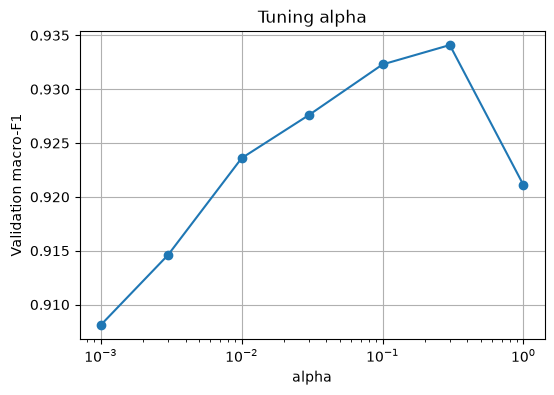

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(tuning_df['alpha'], tuning_df['val_macro_f1'], marker='o')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Validation macro-F1')
plt.title('Tuning alpha')
plt.grid(True)
plt.show()

## 5. Train the final model

A new model with the best alpha, trained on the training set.

In [6]:
final_model = build_pipeline(best_alpha)
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U19](14,)","['abroad','address','app_error',...,'joint_account','latest_transactions', 'pay_bill']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


## 6. Evaluate on the synthetic test set

Scored once with the shared `evaluate()`, which also saves the confusion matrix and adds a row to
`results/metrics.csv`. **Run this cell only once.** The predictions are saved for the benchmark.

In [7]:
def save_predictions(texts, labels, preds, dataset_name):
    os.makedirs('../results/predictions', exist_ok=True)
    pd.DataFrame({'text': texts.values, 'intent': labels.values, 'pred': preds}).to_csv(
        f'../results/predictions/tfidf_nb_{dataset_name}.csv', index=False
    )

test_preds = final_model.predict(X_test)
evaluate(y_test, test_preds, 'tfidf_nb', 'synthetic_test', out_dir='../results')
save_predictions(X_test, y_test, test_preds, 'synthetic_test')

=== tfidf_nb on synthetic_test ===
Accuracy: 0.9314   Macro-F1: 0.9298

                     precision    recall  f1-score   support

             abroad       0.88      0.69      0.77        32
            address       1.00      1.00      1.00        32
          app_error       0.97      1.00      0.99        33
          atm_limit       0.89      0.97      0.93        32
            balance       0.94      0.94      0.94        32
      business_loan       0.97      0.97      0.97        33
        card_issues       0.87      0.81      0.84        32
       cash_deposit       0.94      0.91      0.92        33
       direct_debit       0.91      0.97      0.94        32
             freeze       0.83      0.91      0.87        32
 high_value_payment       1.00      0.97      0.98        32
      joint_account       0.94      1.00      0.97        32
latest_transactions       0.91      0.91      0.91        32
           pay_bill       1.00      1.00      1.00        33

           

## 7. Evaluate on MINDS-14 (real customer calls)

The same model, with no retraining. **Run this cell only once.**

In [8]:
minds_preds = final_model.predict(X_minds)
evaluate(y_minds, minds_preds, 'tfidf_nb', 'minds14', out_dir='../results')
save_predictions(X_minds, y_minds, minds_preds, 'minds14')

=== tfidf_nb on minds14 ===
Accuracy: 0.8231   Macro-F1: 0.8189

                     precision    recall  f1-score   support

             abroad       0.60      0.81      0.69       115
            address       0.90      1.00      0.95       131
          app_error       0.71      0.78      0.74       125
          atm_limit       0.95      0.91      0.93       137
            balance       0.66      0.98      0.79       131
      business_loan       0.97      0.92      0.94       130
        card_issues       0.84      0.46      0.60       138
       cash_deposit       0.94      0.84      0.89       135
       direct_debit       0.94      0.86      0.90       125
             freeze       0.80      0.84      0.82       128
 high_value_payment       0.66      0.52      0.58       126
      joint_account       0.93      0.98      0.95       129
latest_transactions       0.80      0.86      0.83       129
           pay_bill       0.97      0.76      0.85       130

           accurac

## 8. Save the model

The whole pipeline (TF-IDF + Naive Bayes), so it can be used directly on raw text.

In [9]:
os.makedirs('../models', exist_ok=True)
joblib.dump(final_model, '../models/tfidf_nb.joblib')
print('Model saved to ../models/tfidf_nb.joblib')

Model saved to ../models/tfidf_nb.joblib


## 9. Comparison with logistic regression

Both models use the same features, so this isolates the effect of the classifier.

In [10]:
metrics = pd.read_csv('../results/metrics.csv')
comparison = metrics[metrics['model'].isin(['tfidf_nb', 'tfidf_lr'])]
comparison.pivot(index='model', columns='dataset', values='macro_f1')[['synthetic_test', 'minds14']]

dataset,synthetic_test,minds14
model,,
tfidf_lr,0.9386,0.8640
tfidf_nb,0.9298,0.8189


## 10. Conclusion

- **Best alpha: 0.3** (validation macro-F1 0.9341). The score rises up to 0.3 and drops at 1.0,
  so the peak lies inside the searched range.
- **Synthetic test:** accuracy 0.9314, macro-F1 0.9298. Logistic regression on the same features
  scores 0.9386, but the paired bootstrap interval of the difference includes 0, so the two are tied here.
- **MINDS-14 (real calls):** accuracy 0.8231, macro-F1 0.8189, the lowest of all models. Logistic
  regression is clearly better on real data (+0.045, paired bootstrap interval [0.033, 0.059]).
- **Drop from synthetic to real data: 11.1 points**, the largest of all models (logistic regression: 7.5).
  With identical features, the difference comes from the classifier. Naive Bayes treats every word as
  independent evidence and relies on word frequencies seen in training, so it suffers more when real
  callers use different wording and speech-recognition errors. Logistic regression learns weights for all
  features together and generalizes better.
- **Weakest intents on MINDS-14:** `high_value_payment` (F1 0.58), `card_issues` (0.60) and `abroad`
  (0.69), the same confusable card and payment intents that are hard for the other models, but worse.

Naive Bayes is the simplest model in our benchmark and the bottom of the ladder:
**Naive Bayes -> logistic regression -> sentence embeddings -> fine-tuned transformers -> Jev.**